In [1]:
import torch 
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [2]:
x_train = torch.linspace(0, 2 * torch.pi, 1000).unsqueeze(1)
y_train = torch.sin(x_train)

x_train.shape, y_train.shape

(torch.Size([1000, 1]), torch.Size([1000, 1]))

In [3]:
class model(nn.Module):
    def __init__(self):
        super(model, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 4),
            nn.ReLU(),
            nn.Linear(4, 4),
            nn.ReLU(),
            nn.Linear(4,1)
        )
    
    def forward(self, x):
        return self.net(x)
    
model = model()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [4]:
# Training loop
num_epochs = 20000
loss_history = []

for epoch in range(num_epochs):
    model.train()
    
    # Forward pass
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)
    loss_history.append(loss.item())
    
    # Backward pass and optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    # Print loss every 100 epochs
    if (epoch + 1) % 1000 == 0:
        print(f"Epoch [{epoch + 1}/{num_epochs}], Loss: {loss.item():.4f}")

Epoch [1000/20000], Loss: 0.0034
Epoch [2000/20000], Loss: 0.0033
Epoch [3000/20000], Loss: 0.0033
Epoch [4000/20000], Loss: 0.0033
Epoch [5000/20000], Loss: 0.0033
Epoch [6000/20000], Loss: 0.0033
Epoch [7000/20000], Loss: 0.0033
Epoch [8000/20000], Loss: 0.0033
Epoch [9000/20000], Loss: 0.0033
Epoch [10000/20000], Loss: 0.0033
Epoch [11000/20000], Loss: 0.0033
Epoch [12000/20000], Loss: 0.0033
Epoch [13000/20000], Loss: 0.0033
Epoch [14000/20000], Loss: 0.0033
Epoch [15000/20000], Loss: 0.0033
Epoch [16000/20000], Loss: 0.0033
Epoch [17000/20000], Loss: 0.0033
Epoch [18000/20000], Loss: 0.0033
Epoch [19000/20000], Loss: 0.0033
Epoch [20000/20000], Loss: 0.0033


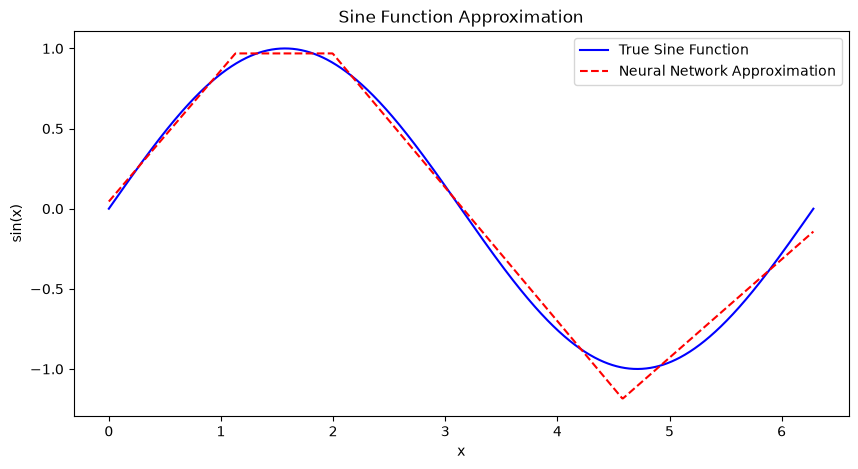

In [5]:

# Plot the results
model.eval()
x_test = torch.linspace(0, 2 * torch.pi, 1000).unsqueeze(1)
y_test = torch.sin(x_test)
y_approx = model(x_test).detach()

plt.figure(figsize=(10, 5))
plt.plot(x_test, y_test, label="True Sine Function", color="blue")
plt.plot(x_test, y_approx, label="Neural Network Approximation", color="red", linestyle="--")
plt.legend()
plt.title("Sine Function Approximation")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.show()